# 01 · Exploratory data analysis

What the Sparkov card-transaction data looks like before any model sees it.

- **Simulated data.** Sparkov is generated, so everything below describes the generator's
  rules, not real cardholder behaviour.
- **Training partition only.** This notebook reads `fraudTrain` rows and nothing from the
  public test partition, which stays unread until the final evaluation.
- **Read-only.** No logic lives here. Features come from `fraudlens.features`, splits from
  `fraudlens.data.splits`. Run `make data features` first.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if not Path("data").exists():  # executed from notebooks/
    os.chdir("..")

from fraudlens.common.paths import TRAINVAL_FEATURES_PATH, TRANSACTIONS_PATH
from fraudlens.data.splits import assign_roles, split_bounds
from fraudlens.features.definitions import HISTORY_MAX_ENTRIES

GENUINE, FRAUD = "#2a78d6", "#eb6834"
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#c9c8c2",
        "axes.grid": True,
        "grid.color": "#e8e7e2",
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.labelcolor": "#52514e",
        "xtick.color": "#52514e",
        "ytick.color": "#52514e",
        "font.size": 9,
        "figure.dpi": 80,
    }
)
pd.set_option("display.width", 160)

txns = pd.read_parquet(TRANSACTIONS_PATH, filters=[("partition", "==", "train")])
features = pd.read_parquet(TRAINVAL_FEATURES_PATH)
df = txns.merge(
    features.drop(columns=["card_id", "event_ts", "is_fraud", "amount", "category"]),
    on="transaction_id",
    validate="one_to_one",
)
df["when"] = pd.to_datetime(df["event_ts"], unit="s")
fraud = df["is_fraud"] == 1

print(f"{len(df):,} transactions, {fraud.sum():,} fraud ({fraud.mean():.2%})")
print(f"{df['card_id'].nunique():,} cards, {df['merchant_id'].nunique():,} merchants")
print(f"from {df['when'].min()} to {df['when'].max()}")

1,296,675 transactions, 7,506 fraud (0.58%)
983 cards, 693 merchants
from 2019-01-01 00:00:18 to 2020-06-21 12:13:37


## 1. Class balance over time

Volume and fraud rate per calendar month. They are drawn as two panels because they are
two different measures; they never share an axis.

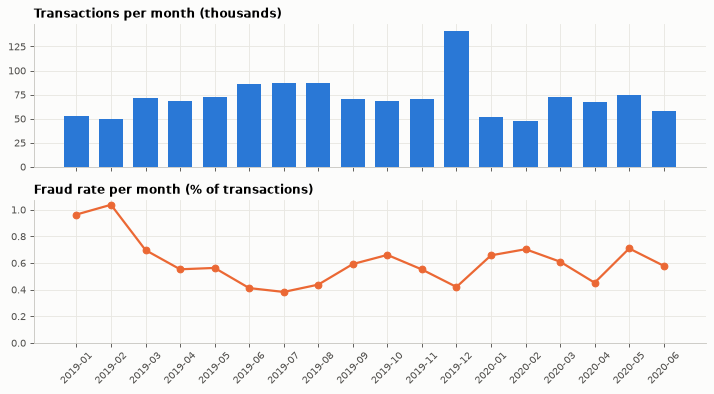

,transactions,frauds,fraud_rate_%
when,,,
2019-01,52525,506,0.963
2019-02,49866,517,1.037
2019-03,70939,494,0.696
2019-04,68078,376,0.552
2019-05,72532,408,0.563
2019-06,86064,354,0.411
2019-07,86596,331,0.382
2019-08,87359,382,0.437
2019-09,70652,418,0.592


In [2]:
monthly = df.groupby(df["when"].dt.to_period("M"))["is_fraud"].agg(
    transactions="size", frauds="sum", fraud_rate="mean"
)
labels = monthly.index.strftime("%Y-%m")

fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
top.bar(labels, monthly["transactions"] / 1_000, color=GENUINE, width=0.7)
top.set_title("Transactions per month (thousands)")
bottom.plot(labels, monthly["fraud_rate"] * 100, color=FRAUD, linewidth=2, marker="o")
bottom.set_ylim(0, None)
bottom.set_title("Fraud rate per month (% of transactions)")
bottom.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

monthly.assign(fraud_rate=(monthly["fraud_rate"] * 100).round(3)).rename(
    columns={"fraud_rate": "fraud_rate_%"}
)

## 2. Amount by class

Amounts span four orders of magnitude, so the horizontal axis is logarithmic. Each curve
is normalised to its own class, otherwise fraud would be invisible.

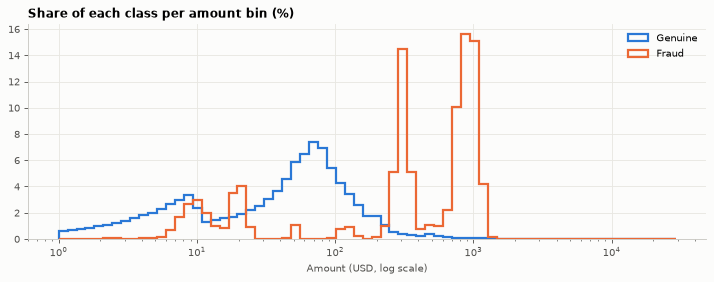

Fraud is 0.58% of transactions and 4.37% of dollar value.


,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
fraud,7506.0,531.32,390.56,1.06,245.66,396.50,900.88,1376.04
genuine,1289169.0,67.67,154.01,1.00,9.61,47.28,82.54,28948.90


In [3]:
bins = np.logspace(0, np.log10(df["amount"].max()), 70)
fig, ax = plt.subplots(figsize=(9, 3.6))
for mask, colour, name in ((~fraud, GENUINE, "Genuine"), (fraud, FRAUD, "Fraud")):
    ax.hist(
        df.loc[mask, "amount"],
        bins=bins,
        weights=np.full(mask.sum(), 100 / mask.sum()),
        histtype="step",
        linewidth=2,
        color=colour,
        label=name,
    )
ax.set_xscale("log")
ax.set_xlabel("Amount (USD, log scale)")
ax.set_title("Share of each class per amount bin (%)")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

value_share = df.loc[fraud, "amount"].sum() / df["amount"].sum()
print(f"Fraud is {fraud.mean():.2%} of transactions and {value_share:.2%} of dollar value.")
df.groupby(df["is_fraud"].map({0: "genuine", 1: "fraud"}))["amount"].describe().round(2)

## 3. Fraud by hour and by category

Hour is in UTC, the same clock the `hour` and `is_night` features use.

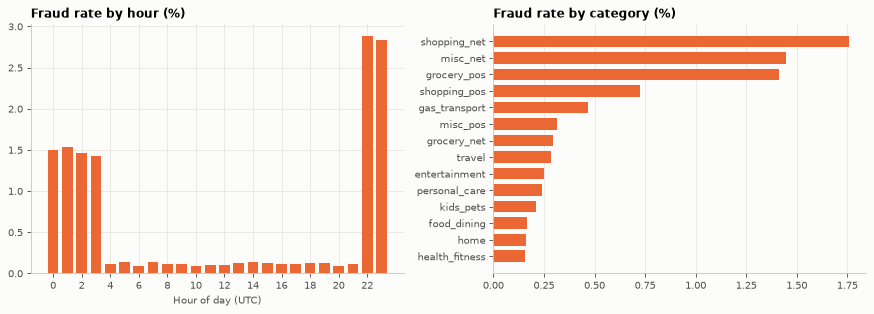

Fraud rate 22:00-05:59: 1.66%
Fraud rate 06:00-21:59: 0.11%
Share of all fraud that happens 22:00-05:59: 86.2%


In [4]:
by_hour = df.groupby("hour")["is_fraud"].mean() * 100
by_category = (df.groupby("category")["is_fraud"].mean() * 100).sort_values()

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
left.bar(by_hour.index, by_hour.to_numpy(), color=FRAUD, width=0.75)
left.set_xticks(range(0, 24, 2))
left.set_xlabel("Hour of day (UTC)")
left.set_title("Fraud rate by hour (%)")
right.barh(by_category.index, by_category.to_numpy(), color=FRAUD, height=0.7)
right.set_title("Fraud rate by category (%)")
right.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

night = df["is_night"] == 1
print(f"Fraud rate 22:00-05:59: {df.loc[night, 'is_fraud'].mean():.2%}")
print(f"Fraud rate 06:00-21:59: {df.loc[~night, 'is_fraud'].mean():.2%}")
print(f"Share of all fraud that happens 22:00-05:59: {night[fraud].mean():.1%}")

## 4. Merchant coordinates against home

If merchant coordinates were real places, their offset from the cardholder's home would
pile up near zero with a long tail. The question is whether they carry any signal.

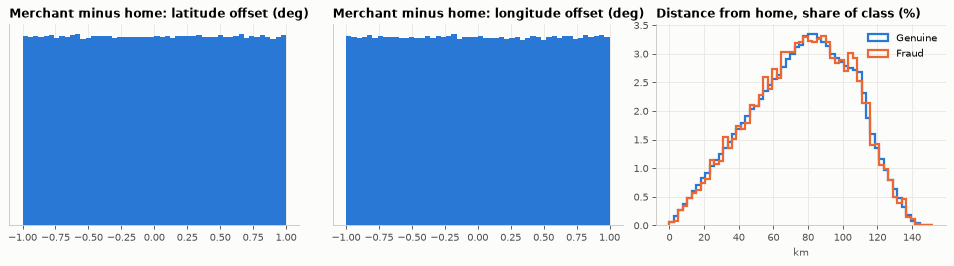

,latitude offset (deg),longitude offset (deg)
count,1.296675e+06,1.296675e+06
mean,-3.000000e-04,-1.000000e-04
std,5.775000e-01,5.777000e-01
min,-1.000000e+00,-1.000000e+00
25%,-5.010000e-01,-5.000000e-01
50%,1.000000e-04,-1.100000e-03
75%,5.001000e-01,5.006000e-01
max,1.000000e+00,1.000000e+00


,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
fraud,7506.0,76.27,28.75,0.74,55.63,77.93,98.39,144.52
genuine,1289169.0,76.11,29.12,0.02,55.33,78.23,98.50,152.12


In [5]:
offsets = pd.DataFrame(
    {
        "latitude offset (deg)": df["merchant_lat"] - df["home_lat"],
        "longitude offset (deg)": df["merchant_long"] - df["home_long"],
    }
)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, column in zip(axes[:2], offsets.columns, strict=True):
    ax.hist(offsets[column], bins=50, color=GENUINE)
    ax.set_title(f"Merchant minus home: {column}")
    ax.set_yticks([])
edges = np.linspace(0, df["dist_home_km"].max(), 60)
for mask, colour, name in ((~fraud, GENUINE, "Genuine"), (fraud, FRAUD, "Fraud")):
    axes[2].hist(
        df.loc[mask, "dist_home_km"],
        bins=edges,
        weights=np.full(mask.sum(), 100 / mask.sum()),
        histtype="step",
        linewidth=2,
        color=colour,
        label=name,
    )
axes[2].set_title("Distance from home, share of class (%)")
axes[2].set_xlabel("km")
axes[2].legend(frameon=False)
fig.tight_layout()
plt.show()

display(offsets.describe().round(4))
df.groupby(df["is_fraud"].map({0: "genuine", 1: "fraud"}))["dist_home_km"].describe().round(2)

## 5. What the history features see

How much history a typical transaction has, whether the 500-entry cap ever binds, and how
far apart the two classes sit on the main pattern and velocity features.

In [6]:
print(df["n_prior_30d"].describe().round(1).to_string())
at_cap = (df["n_prior_30d"] == HISTORY_MAX_ENTRIES).sum()
print(f"\nRows at the {HISTORY_MAX_ENTRIES}-entry history cap: {at_cap}")
print(f"Rows with no prior transaction in 30 days: {(df['n_prior_30d'] == 0).sum():,}")
same_second = df.duplicated(["card_id", "event_ts"], keep=False).sum()
print(f"Rows sharing a card and a second with another row: {same_second}")

columns = [
    "amount",
    "amt_ratio_30d",
    "amt_zscore_30d",
    "txn_count_1h",
    "txn_count_24h",
    "amt_sum_24h",
    "secs_since_prev",
    "dist_prev_km",
    "speed_prev_kmh",
    "is_new_merchant_30d",
    "is_night",
]
df.groupby(df["is_fraud"].map({0: "genuine", 1: "fraud"}))[columns].median().T.round(3)

count    1296675.0
mean         103.0
std           52.6
min            0.0
25%           65.0
50%           98.0
75%          135.0
max          361.0

Rows at the 500-entry history cap: 0
Rows with no prior transaction in 30 days: 983


Rows sharing a card and a second with another row: 40


is_fraud,fraud,genuine
amount,396.505,47.280
amt_ratio_30d,4.334,0.668
amt_zscore_30d,2.150,-0.226
txn_count_1h,0.000,0.000
txn_count_24h,4.000,3.000
amt_sum_24h,1674.155,171.140
secs_since_prev,4908.000,16623.000
dist_prev_km,99.594,100.789
speed_prev_kmh,64.323,19.939
is_new_merchant_30d,1.000,1.000


## 6. The time split

Boundaries and sizes of the split defined in `fraudlens.data.splits`: training, a 7-day
gap that is discarded, then validation cut 60/40 by time.

In [7]:
ts = df["event_ts"].to_numpy()
bounds = split_bounds(ts)
for name in ("train_end_ts", "valid_start_ts", "calib_start_ts"):
    print(f"{name:15s} {pd.to_datetime(getattr(bounds, name), unit='s')}")

split = (
    df.assign(role=assign_roles(ts, bounds))
    .groupby("role")["is_fraud"]
    .agg(rows="size", frauds="sum", fraud_rate="mean")
)
split.loc[["train", "gap", "valid_early", "valid_late"]].assign(
    fraud_rate=lambda t: (t["fraud_rate"] * 100).round(3)
).rename(columns={"fraud_rate": "fraud_rate_%"})

train_end_ts    2020-01-21 15:04:36
valid_start_ts  2020-01-28 15:04:36
calib_start_ts  2020-05-02 11:09:29


,rows,frauds,fraud_rate_%
role,,,
train,960514,5460,0.568
gap,11992,63,0.525
valid_early,194501,1151,0.592
valid_late,129668,832,0.642


## Findings

Every statement here is read off the outputs above.

1. **Fraud is rare and its rate wanders.** The monthly fraud rate stays under about one
   percent and moves from month to month without a trend, while volume has a strong
   seasonal peak in December. A time-ordered split is the only honest one.
2. **Amount carries most of the signal.** Fraud amounts fall into a few narrow bands, most
   of them far above the typical genuine purchase, and stop well short of the genuine
   maximum: the very largest purchases are all genuine. Bands this sharp are a signature
   of the generator, and a tree model will find them easily. Fraud's share of dollar value
   is several times its share of transactions, which is why dollar recall is reported next
   to plain recall.
3. **Fraud keeps night hours.** The fraud rate is many times higher from 22:00 to 03:59
   than through the day, and most fraud falls in the night window. Hours 04 and 05 look
   like daytime, so `hour` adds information beyond the `is_night` flag.
4. **Category matters.** Online shopping, miscellaneous online and in-person grocery
   purchases have the highest fraud rates.
5. **Merchant coordinates are noise around home.** Both offsets are flat between exactly
   -1 and +1 degree, and distance from home has the same distribution for fraud and
   genuine transactions. `dist_home_km` should therefore be weak. `dist_prev_km` is built
   from the same coordinates, so any signal in `speed_prev_kmh` comes from the time gap,
   not the distance. This is a property of the simulator and would not hold on real data.
6. **Spending pattern and velocity separate the classes.** The median fraud is several
   times the card's 30-day average, follows the previous purchase much sooner, and comes
   with a far larger 24-hour spend.
7. **The history cap never binds here.** No row reaches the 500-entry cap, so on this
   dataset the cap is a safety limit for serving rather than something that shapes
   features.